# Práctica 3: Análisis Exploratorio de Datos — Titanic

## Business Understanding

## ETAPA 1: Extracción y Exploración Inicial

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.style.use("ggplot")
pd.set_option("display.max_columns", None)

## ETAPA 2: Data Understanding

### Paso 1: Estructura, dimensiones y duplicados

In [2]:
# 1. Cargar el dataset
df = pd.read_csv("titanic3.csv")
df.head()

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"


In [3]:
# 2. Dimensión de los datos
print(f"Filas: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")
df.shape

Filas: 1309
Columnas: 14


(1309, 14)

In [4]:
# 3. Estructura y tipos de datos
df.info()
print("\nTipos de datos:")
print(df.dtypes)

<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pclass     1309 non-null   int64  
 1   survived   1309 non-null   int64  
 2   name       1309 non-null   str    
 3   sex        1309 non-null   str    
 4   age        1046 non-null   float64
 5   sibsp      1309 non-null   int64  
 6   parch      1309 non-null   int64  
 7   ticket     1309 non-null   str    
 8   fare       1308 non-null   float64
 9   cabin      295 non-null    str    
 10  embarked   1307 non-null   str    
 11  boat       486 non-null    str    
 12  body       121 non-null    float64
 13  home.dest  745 non-null    str    
dtypes: float64(3), int64(4), str(7)
memory usage: 143.3 KB

Tipos de datos:
pclass         int64
survived       int64
name             str
sex              str
age          float64
sibsp          int64
parch          int64
ticket           str
fare         float6

In [5]:
# 4. Valores duplicados
duplicados = df.duplicated().sum()
print(f"Registros duplicados: {duplicados}")

Registros duplicados: 0


### Paso 2: Valores nulos y columnas a eliminar

In [6]:
# 5. Valores nulos por columna (orden descendente)
nulos = df.isnull().sum().sort_values(ascending=False)
nulos

body         1188
cabin        1014
boat          823
home.dest     564
age           263
embarked        2
fare            1
sibsp           0
name            0
survived        0
pclass          0
sex             0
parch           0
ticket          0
dtype: int64

In [7]:
# 6. Cantidad de nulos y porcentaje
resumen_nulos = pd.DataFrame({
    "Cantidad de nulos": df.isnull().sum(),
    "Porcentaje": round(df.isnull().sum() / len(df) * 100, 2)
}).sort_values("Cantidad de nulos", ascending=False)

resumen_nulos

,Cantidad de nulos,Porcentaje
body,1188,90.76
cabin,1014,77.46
boat,823,62.87
home.dest,564,43.09
age,263,20.09
embarked,2,0.15
fare,1,0.08
sibsp,0,0.00
name,0,0.00
survived,0,0.00


#### a) Estadísticas clave del dataset

In [8]:
df.describe(include="all")

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
count,1309.000000,1309.000000,1309,1309,1046.000000,1309.000000,1309.000000,1309,1308.000000,295,1307,486,121.000000,745
unique,NaN,NaN,1307,2,NaN,NaN,NaN,929,NaN,186,3,27,NaN,369
top,NaN,NaN,"Connolly, Miss. Kate",male,NaN,NaN,NaN,CA. 2343,NaN,C23 C25 C27,S,13,NaN,"New York, NY"
freq,NaN,NaN,2,843,NaN,NaN,NaN,11,NaN,6,914,39,NaN,64
mean,2.294882,0.381971,NaN,NaN,29.881135,0.498854,0.385027,NaN,33.295479,NaN,NaN,NaN,160.809917,NaN
std,0.837836,0.486055,NaN,NaN,14.413500,1.041658,0.865560,NaN,51.758668,NaN,NaN,NaN,97.696922,NaN
min,1.000000,0.000000,NaN,NaN,0.166700,0.000000,0.000000,NaN,0.000000,NaN,NaN,NaN,1.000000,NaN
25%,2.000000,0.000000,NaN,NaN,21.000000,0.000000,0.000000,NaN,7.895800,NaN,NaN,NaN,72.000000,NaN
50%,3.000000,0.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN,NaN,155.000000,NaN
75%,3.000000,1.000000,NaN,NaN,39.000000,1.000000,0.000000,NaN,31.275000,NaN,NaN,NaN,256.000000,NaN


#### b) Selección de columnas a eliminar

In [9]:
# Columnas candidatas a eliminar por exceso de nulos o baja relevancia
columnas_eliminar = ["body", "cabin", "boat", "home.dest", "ticket"]
print("Columnas a eliminar:", columnas_eliminar)
print(resumen_nulos.loc[[c for c in columnas_eliminar if c in resumen_nulos.index]])

Columnas a eliminar: ['body', 'cabin', 'boat', 'home.dest', 'ticket']
           Cantidad de nulos  Porcentaje
body                    1188       90.76
cabin                   1014       77.46
boat                     823       62.87
home.dest                564       43.09
ticket                     0        0.00


### Paso 3: Valores únicos por columna

In [10]:
# 7. Valores únicos por columna
df.nunique().sort_values(ascending=False)

name         1307
ticket        929
home.dest     369
fare          281
cabin         186
body          121
age            98
boat           27
parch           8
sibsp           7
pclass          3
embarked        3
sex             2
survived        2
dtype: int64

In [11]:
# 8. Columnas con menos de 10 valores únicos
for columna in df.columns:
    if df[columna].nunique() < 10:
        print(f"{columna} ({df[columna].nunique()} únicos): {df[columna].unique()}")

pclass (3 únicos): [1 2 3]
survived (2 únicos): [1 0]
sex (2 únicos): <StringArray>
['female', 'male']
Length: 2, dtype: str
sibsp (7 únicos): [0 1 2 3 4 5 8]
parch (8 únicos): [0 2 1 4 3 5 6 9]
embarked (3 únicos): <StringArray>
['S', 'C', nan, 'Q']
Length: 4, dtype: str


### Paso 4: Análisis exploratorio de datos

In [12]:
# 1. Total de pasajeros
total_pasajeros = len(df)
print(f"Total de pasajeros: {total_pasajeros}")

Total de pasajeros: 1309


In [13]:
# 2. Conteo y porcentaje de sobrevivientes / no sobrevivientes
surv_counts = df["survived"].value_counts().rename({0: "No sobrevivió", 1: "Sobrevivió"})
surv_pct = round(df["survived"].value_counts(normalize=True) * 100, 2)
surv_pct.index = surv_pct.index.map({0: "No sobrevivió", 1: "Sobrevivió"})

df_supervivencia = pd.DataFrame({
    "Conteo": surv_counts,
    "Porcentaje": surv_pct
})
df_supervivencia

,Conteo,Porcentaje
survived,,
No sobrevivió,809,61.8
Sobrevivió,500,38.2


In [14]:
# 3. Conteo y porcentaje de pasajeros por sexo
df_sexo = pd.DataFrame({
    "Conteo": df["sex"].value_counts(),
    "Porcentaje": round(df["sex"].value_counts(normalize=True) * 100, 2)
})
df_sexo

,Conteo,Porcentaje
sex,,
male,843,64.4
female,466,35.6


In [15]:
# 4. Sobrevivientes por sexo y porcentaje de supervivencia
surv_por_sexo = df.groupby("sex")["survived"].agg(["sum", "count", "mean"])
surv_por_sexo.columns = ["Sobrevivientes", "Total", "Tasa_supervivencia"]
surv_por_sexo["Porcentaje"] = round(surv_por_sexo["Tasa_supervivencia"] * 100, 2)
surv_por_sexo

,Sobrevivientes,Total,Tasa_supervivencia,Porcentaje
sex,,,,
female,339,466,0.727468,72.75
male,161,843,0.190985,19.10


In [16]:
# 5. Conteo y porcentaje de pasajeros por clase
df_clase = pd.DataFrame({
    "Conteo": df["pclass"].value_counts().sort_index(),
    "Porcentaje": round(df["pclass"].value_counts(normalize=True).sort_index() * 100, 2)
})
df_clase.index.name = "Clase"
df_clase

,Conteo,Porcentaje
Clase,,
1,323,24.68
2,277,21.16
3,709,54.16


In [17]:
# 6. Conteo de hombres y mujeres por clase
sexo_por_clase = pd.crosstab(df["pclass"], df["sex"], margins=True, margins_name="Total")
sexo_por_clase

sex,female,male,Total
pclass,,,
1,144,179,323
2,106,171,277
3,216,493,709
Total,466,843,1309


In [18]:
# 7. Porcentaje de supervivencia según sibsp
surv_sibsp = df.groupby("sibsp")["survived"].agg(["count", "sum", "mean"])
surv_sibsp.columns = ["Total", "Sobrevivientes", "Tasa"]
surv_sibsp["Porcentaje"] = round(surv_sibsp["Tasa"] * 100, 2)
surv_sibsp

,Total,Sobrevivientes,Tasa,Porcentaje
sibsp,,,,
0,891,309,0.346801,34.68
1,319,163,0.510972,51.10
2,42,19,0.452381,45.24
3,20,6,0.300000,30.00
4,22,3,0.136364,13.64
5,6,0,0.000000,0.00
8,9,0,0.000000,0.00


In [19]:
# 8. Porcentaje de supervivencia según parch
surv_parch = df.groupby("parch")["survived"].agg(["count", "sum", "mean"])
surv_parch.columns = ["Total", "Sobrevivientes", "Tasa"]
surv_parch["Porcentaje"] = round(surv_parch["Tasa"] * 100, 2)
surv_parch

,Total,Sobrevivientes,Tasa,Porcentaje
parch,,,,
0,1002,336,0.335329,33.53
1,170,100,0.588235,58.82
2,113,57,0.504425,50.44
3,8,5,0.625000,62.50
4,6,1,0.166667,16.67
5,6,1,0.166667,16.67
6,2,0,0.000000,0.00
9,2,0,0.000000,0.00


### Paso 5: Gráficas con Matplotlib

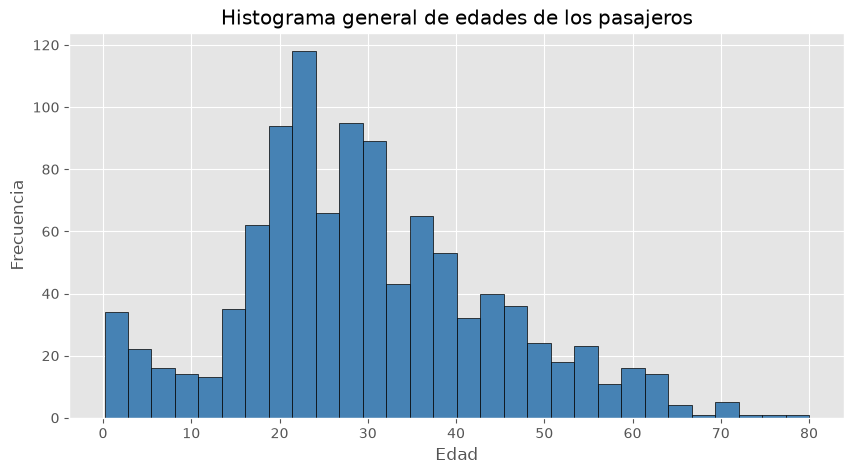

In [20]:
# 1. Histograma general por edades
plt.figure(figsize=(10, 5))
plt.hist(df["age"].dropna(), bins=30, edgecolor="black", color="steelblue")
plt.title("Histograma general de edades de los pasajeros")
plt.xlabel("Edad")
plt.ylabel("Frecuencia")
plt.show()

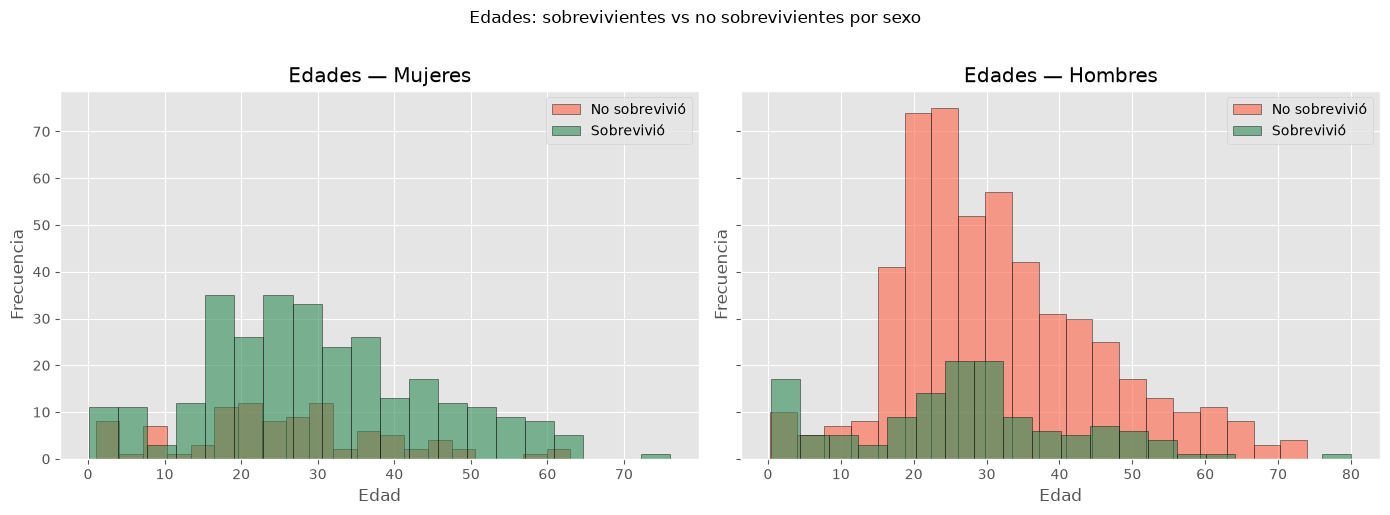

In [21]:
# 2. Histograma por edades: sobrevivientes vs no, por sexo
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, sexo, titulo in zip(axes, ["female", "male"], ["Mujeres", "Hombres"]):
    subset = df[df["sex"] == sexo]
    ax.hist(
        subset.loc[subset["survived"] == 0, "age"].dropna(),
        bins=20, alpha=0.6, label="No sobrevivió", color="tomato", edgecolor="black"
    )
    ax.hist(
        subset.loc[subset["survived"] == 1, "age"].dropna(),
        bins=20, alpha=0.6, label="Sobrevivió", color="seagreen", edgecolor="black"
    )
    ax.set_title(f"Edades — {titulo}")
    ax.set_xlabel("Edad")
    ax.set_ylabel("Frecuencia")
    ax.legend()

plt.suptitle("Edades: sobrevivientes vs no sobrevivientes por sexo", y=1.02)
plt.tight_layout()
plt.show()

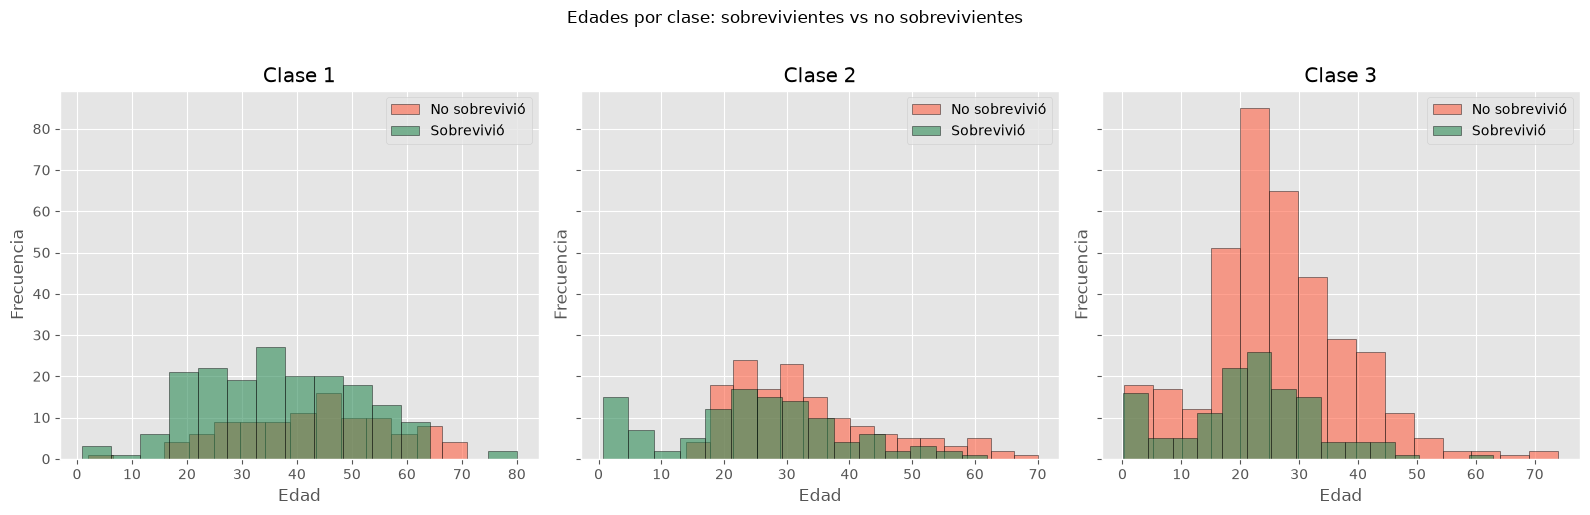

In [22]:
# 3. Histograma por clase: edad de sobrevivientes y no sobrevivientes
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

for ax, clase in zip(axes, [1, 2, 3]):
    subset = df[df["pclass"] == clase]
    ax.hist(
        subset.loc[subset["survived"] == 0, "age"].dropna(),
        bins=15, alpha=0.6, label="No sobrevivió", color="tomato", edgecolor="black"
    )
    ax.hist(
        subset.loc[subset["survived"] == 1, "age"].dropna(),
        bins=15, alpha=0.6, label="Sobrevivió", color="seagreen", edgecolor="black"
    )
    ax.set_title(f"Clase {clase}")
    ax.set_xlabel("Edad")
    ax.set_ylabel("Frecuencia")
    ax.legend()

plt.suptitle("Edades por clase: sobrevivientes vs no sobrevivientes", y=1.02)
plt.tight_layout()
plt.show()

## ETAPA 3: Data Preparation

In [23]:
# 1. Copia del dataframe
df_prep = df.copy()
print(f"Copia creada. Shape: {df_prep.shape}")

Copia creada. Shape: (1309, 14)


In [24]:
# 2. Seleccionar columnas relevantes
columnas_relevantes = ["pclass", "survived", "name", "sex", "age", "sibsp", "parch", "fare", "embarked"]
df_prep = df_prep[columnas_relevantes]
df_prep.head()

,pclass,survived,name,sex,age,sibsp,parch,fare,embarked
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,211.3375,S
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,151.5500,S
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,151.5500,S
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,151.5500,S
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,151.5500,S


In [25]:
# 3. Verificar estructura
df_prep.info()
print("\nNulos actuales:")
print(df_prep.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   pclass    1309 non-null   int64  
 1   survived  1309 non-null   int64  
 2   name      1309 non-null   str    
 3   sex       1309 non-null   str    
 4   age       1046 non-null   float64
 5   sibsp     1309 non-null   int64  
 6   parch     1309 non-null   int64  
 7   fare      1308 non-null   float64
 8   embarked  1307 non-null   str    
dtypes: float64(2), int64(4), str(3)
memory usage: 92.2 KB

Nulos actuales:
pclass        0
survived      0
name          0
sex           0
age         263
sibsp         0
parch         0
fare          1
embarked      2
dtype: int64


In [26]:
# 4. sex a numérico (female -> 0, male -> 1)
df_prep["sex"] = df_prep["sex"].map({"female": 0, "male": 1})
print("Valores únicos de sex:", df_prep["sex"].unique())
df_prep[["name", "sex"]].head()

Valores únicos de sex: [0 1]


,name,sex
0,"Allen, Miss. Elisabeth Walton",0
1,"Allison, Master. Hudson Trevor",1
2,"Allison, Miss. Helen Loraine",0
3,"Allison, Mr. Hudson Joshua Creighton",1
4,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",0


In [28]:
# 5. age y fare = mediana; embarked = moda
mediana_age = df_prep["age"].median()
mediana_fare = df_prep["fare"].median()
moda_embarked = df_prep["embarked"].mode()[0]

print(f"Mediana age: {mediana_age}")
print(f"Mediana fare: {mediana_fare}")
print(f"Moda embarked: {moda_embarked}")

df_prep["age"] = df_prep["age"].fillna(mediana_age)
df_prep["fare"] = df_prep["fare"].fillna(mediana_fare)
df_prep["embarked"] = df_prep["embarked"].fillna(moda_embarked)

Mediana age: 28.0
Mediana fare: 14.4542
Moda embarked: S


In [29]:
# 6. Verificar que no queden nulos
print("Nulos restantes por columna:")
print(df_prep.isnull().sum())
print(f"\nTotal de nulos: {df_prep.isnull().sum().sum()}")
df_prep.info()

Nulos restantes por columna:
pclass      0
survived    0
name        0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
dtype: int64

Total de nulos: 0
<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   pclass    1309 non-null   int64  
 1   survived  1309 non-null   int64  
 2   name      1309 non-null   str    
 3   sex       1309 non-null   int64  
 4   age       1309 non-null   float64
 5   sibsp     1309 non-null   int64  
 6   parch     1309 non-null   int64  
 7   fare      1309 non-null   float64
 8   embarked  1309 non-null   str    
dtypes: float64(2), int64(5), str(2)
memory usage: 92.2 KB


In [30]:
# Exportar dataset limpio
archivo_salida = "titanic_limpio.csv"
df_prep.to_csv(archivo_salida, index=False)
print(f"Dataset limpio exportado a: {archivo_salida}")
print(f"Shape final: {df_prep.shape}")
df_prep.head(10)

Dataset limpio exportado a: titanic_limpio.csv
Shape final: (1309, 9)


,pclass,survived,name,sex,age,sibsp,parch,fare,embarked
0,1,1,"Allen, Miss. Elisabeth Walton",0,29.0000,0,0,211.3375,S
1,1,1,"Allison, Master. Hudson Trevor",1,0.9167,1,2,151.5500,S
2,1,0,"Allison, Miss. Helen Loraine",0,2.0000,1,2,151.5500,S
3,1,0,"Allison, Mr. Hudson Joshua Creighton",1,30.0000,1,2,151.5500,S
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",0,25.0000,1,2,151.5500,S
5,1,1,"Anderson, Mr. Harry",1,48.0000,0,0,26.5500,S
6,1,1,"Andrews, Miss. Kornelia Theodosia",0,63.0000,1,0,77.9583,S
7,1,0,"Andrews, Mr. Thomas Jr",1,39.0000,0,0,0.0000,S
8,1,1,"Appleton, Mrs. Edward Dale (Charlotte Lamson)",0,53.0000,2,0,51.4792,S
9,1,0,"Artagaveytia, Mr. Ramon",1,71.0000,0,0,49.5042,C


## Preguntas de negocio

In [ ]:
# 1. Interacción género × clase social
interaccion = df.groupby(["sex", "pclass"])["survived"].agg(["count", "sum", "mean"])
interaccion.columns = ["Total", "Sobrevivientes", "Tasa"]
interaccion["Porcentaje"] = round(interaccion["Tasa"] * 100, 2)
display(interaccion)

tabla = df.pivot_table(values="survived", index="pclass", columns="sex", aggfunc="mean") * 100
tabla.plot(kind="bar", figsize=(8, 5), edgecolor="black")
plt.title("Porcentaje de supervivencia: género × clase")
plt.xlabel("Clase")
plt.ylabel("% Supervivencia")
plt.xticks(rotation=0)
plt.legend(title="Sexo")
plt.tight_layout()
plt.show()

In [ ]:
# 2. Familia pequeña / viajar solo vs supervivencia
df_fam = df.copy()
df_fam["family_size"] = df_fam["sibsp"] + df_fam["parch"] + 1
df_fam["family_cat"] = pd.cut(
    df_fam["family_size"],
    bins=[0, 1, 4, 20],
    labels=["Solo", "Familia pequeña (2-4)", "Familia grande (5+)"]
)

fam_surv = df_fam.groupby("family_cat", observed=True)["survived"].agg(["count", "sum", "mean"])
fam_surv.columns = ["Total", "Sobrevivientes", "Tasa"]
fam_surv["Porcentaje"] = round(fam_surv["Tasa"] * 100, 2)
display(fam_surv)

fam_surv["Porcentaje"].plot(kind="bar", color="teal", edgecolor="black", figsize=(8, 4))
plt.title("Tasa de supervivencia según tamaño de familia")
plt.ylabel("% Supervivencia")
plt.xlabel("Categoría familiar")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [ ]:
# 3. Diferencia de fare entre sobrevivientes y no sobrevivientes
fare_por_surv = df.groupby("survived")["fare"].agg(["count", "mean", "median", "std"])
fare_por_surv.index = fare_por_surv.index.map({0: "No sobrevivió", 1: "Sobrevivió"})
display(fare_por_surv)

df.boxplot(column="fare", by="survived", figsize=(7, 5))
plt.title("Distribución de fare según supervivencia")
plt.suptitle("")
plt.xlabel("Survived (0=No, 1=Sí)")
plt.ylabel("Fare")
plt.tight_layout()
plt.show()

print(
    f"Diferencia de media (sobrevivió - no): "
    f"{df.loc[df['survived']==1, 'fare'].mean() - df.loc[df['survived']==0, 'fare'].mean():.2f}"
)